# 11 — Learning the Gradient Update

Ported from the mfourdvar *Learning how to Learn* chapter.

## From a solver to a learned solver

Every variational analysis in this library is computed by iterating an
update rule on a cost $U$. Vanilla gradient descent is the simplest,

$$
x_{k+1} = x_k - \eta\, \nabla_x U(x_k), \qquad k = 0, \ldots, K-1,
$$

and most of numerical optimisation is a catalogue of better update rules
that use the same gradient more cleverly: momentum keeps a running
average $h_k$ of past gradients, Adam rescales each coordinate by a
running estimate of its variance, Newton's method preconditions by the
inverse Hessian, $x_{k+1} = x_k - [\nabla^2_x U]^{-1} \nabla_x U$. All of
them have the form

$$
x_{k+1} = x_k - g\big(\nabla_x U(x_k),\; x_k,\; h_k\big), \qquad
h_{k+1} = \text{update}(h_k, \nabla_x U(x_k)),
$$

with a hand-designed $g$ and a hand-designed hidden state $h$.

The core 4DVarNet idea, inherited from *learning to learn by gradient
descent by gradient descent* (Andrychowicz et al., 2016), is to make $g$
a small recurrent network $g_\phi$ and to choose $\phi$ by minimising
what we actually care about after $K$ steps:

$$
\phi^* = \underset{\phi}{\arg\min}\;
  \mathbb{E}\, \big\| x_K(\phi) - x_{\text{true}} \big\|^2 ,
\qquad
x_{k+1} = x_k - g_\phi\big(\nabla_x U(x_k),\; x_k,\; h_k\big).
$$

This is the bilevel problem of notebook
[10](10_bilevel_opt_L63.ipynb) with the *update rule* as the outer variable
instead of the cost weights, and it is trained the same way: unroll $K$
steps, back-propagate the reconstruction error through all of them. In
vardax $g_\phi$ is the `ConvLSTMGradMod1D` *gradient modulator* — see the
*learned inner solver* and *gradient modulator family* sections of
chapter [9](../09_4dvarnet.md). The LSTM cell state is the learned
counterpart of a momentum buffer; the convolution lets the step at one
location depend on gradients nearby, a learned, data-dependent
preconditioner.

### Why a learned solver can beat the minimiser of $U$

Gradient descent on $U$ heads for a stationary point of $U$ — with a
neural-network prior the cost is nonconvex, so "the" minimiser is not
guaranteed, only *some* point where $\nabla_x U = 0$. Whichever one it
reaches, the truth is not there: the prior is imperfect and the
observations are noisy, so the stationary points of $U$ sit somewhere
between the data and the prior's fixed points, and more iterations do not
move them closer to $x_{\text{true}}$. The learned solver is trained on
reconstruction error, not on $U$, so it is free to use $\nabla_x U$ as a
*feature* — a signal about where the data and prior disagree — without
being bound to follow it downhill. The gap between the two curves below
therefore mixes two effects: faster progress within the iteration budget,
and the freedom to stop somewhere gradient descent on $U$ would not.

This notebook isolates that one ingredient. The prior $\varphi$ is
pre-trained and **frozen**, and only the modulator is trained, so any
improvement over vanilla gradient descent is attributable to the learned
update rule alone. We then ablate the number of solver steps $K$.

In [1]:
import functools as ft

import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import optax

from vardax import (
    BilinAEPrior1D,
    ConvLSTMGradMod1D,
    init_solver_state_1d,
    simulate_lorenz63,
    solve_4dvarnet_1d,
    solver_step_1d,
)
from vardax._src.utils.masks import regular_mask
from vardax._src.utils.noise import add_gaussian_noise
from vardax._src.utils.patches import extract_patches, trajectory_to_xr_dataset
from vardax._src.utils.preprocessing import xr_to_batch1d
from vardax._src.utils.standardize import apply_standardization, compute_scaler_params

## 1. Lorenz-63 patches and a frozen prior

The data pipeline of notebook [08](08_classical_4dvar_vs_4dvarnet_L63.ipynb):
Lorenz-63 windows split in time, masked every other step, noisy, and
standardised. The prior is a bilinear autoencoder pre-trained on clean
training windows, as in notebook [07](07_prior_pretraining_L63.ipynb), and
then treated as a constant.

In [2]:
key = jax.random.PRNGKey(0)
time_coords, states = simulate_lorenz63(
    key, sigma=10.0, rho=28.0, beta=8.0 / 3.0, dt=0.01, n_steps=5000, n_burn_in=1000
)
ds = trajectory_to_xr_dataset(states, time_coords, feature_names=["X", "Y", "Z"])
# Split the trajectory in time *before* cutting windows, so no window
# straddles the boundary: windows drawn at random from one trajectory and
# split afterwards would leak test timesteps into the training set.
n_time = ds.sizes["time"]
ds_train = extract_patches(ds.isel(time=slice(0, int(0.8 * n_time))), n_patches=64, n_timesteps=20, seed=42)
ds_test = extract_patches(ds.isel(time=slice(int(0.8 * n_time), None)), n_patches=32, n_timesteps=20, seed=43)
ds_train = regular_mask(ds_train, variable="state", obs_interval=2)
ds_test = regular_mask(ds_test, variable="state", obs_interval=2)
ds_train = add_gaussian_noise(ds_train, variable="state", sigma=0.5, seed=0, name="obs")
ds_test = add_gaussian_noise(ds_test, variable="state", sigma=0.5, seed=1, name="obs")
mean, std = compute_scaler_params(ds_train, variable="state", mask_variable="mask")
ds_train = apply_standardization(ds_train, variables=["state", "obs"], mean=mean, std=std)
ds_test = apply_standardization(ds_test, variables=["state", "obs"], mean=mean, std=std)

batch_train = xr_to_batch1d(ds_train, state_var="state", obs_var="obs", mask_var="mask")
batch_test = xr_to_batch1d(ds_test, state_var="state", obs_var="obs", mask_var="mask")
B, T, N = batch_train.input.shape
print(f"train {batch_train.input.shape}, test {batch_test.input.shape}")

train (64, 20, 3), test (32, 20, 3)


In [3]:
prior = BilinAEPrior1D(state_dim=N, latent_dim=8, n_time=T, key=jax.random.PRNGKey(10))
pre_opt = optax.adam(1e-2)
pre_state = pre_opt.init(eqx.filter(prior, eqx.is_array))


@eqx.filter_jit
def pretrain_step(prior, opt_state, x):
    loss, grads = eqx.filter_value_and_grad(lambda p: jnp.mean((x - p(x)) ** 2))(prior)
    updates, opt_state = pre_opt.update(grads, opt_state, prior)
    return eqx.apply_updates(prior, updates), opt_state, loss


for _ in range(300):
    prior, pre_state, pre_loss = pretrain_step(prior, pre_state, batch_train.target)
print(f"prior reconstruction MSE after pre-training: {float(pre_loss):.4f}")

# From here on `prior` is a closed-over constant: nothing below differentiates
# with respect to it.

prior reconstruction MSE after pre-training: 0.0027


## 2. Baseline — vanilla gradient descent

The solver's cost is the one used by `solver_step_1d`:
$U(x) = \|m \odot (x - y)\|^2 + \lambda \|x - \varphi(x)\|^2$ (sums, with
$\lambda = 1$). Vanilla gradient descent takes $K$ steps with a fixed step
size $\eta$ from the masked observations.

The step size is chosen from the observation term, whose gradient is
$2\, m \odot (x - y)$: ignoring the prior, each step with $\eta = 0.1$
closes 20% of the remaining gap at observed points, so that part of the
error decays geometrically as $0.8^k$. The prior term acts everywhere —
it is the only force at unobserved points and it also pulls observed
points toward the reconstruction — so the actual rate depends on how
strongly $\varphi$ couples entries, which is why the baseline improves
steadily but slowly.

In [4]:
PRIOR_WEIGHT = 1.0
ETA = 0.1


def solver_cost(x, batch):
    j_obs = jnp.sum((batch.mask * (x - batch.input)) ** 2)
    j_prior = PRIOR_WEIGHT * jnp.sum((x - prior(x)) ** 2)
    return j_obs + j_prior


def mse(x, batch):
    return jnp.mean((x - batch.target) ** 2)


@ft.partial(jax.jit, static_argnames=("n_steps", "eta"))
def vanilla_gd_trace(batch, n_steps, eta=ETA):
    """Per-step MSE of K vanilla gradient-descent steps (index 0 = init)."""

    def body(x, _):
        x = x - eta * jax.grad(solver_cost)(x, batch)
        return x, mse(x, batch)

    x0 = batch.input * batch.mask
    x_final, trace = jax.lax.scan(body, x0, None, length=n_steps)
    return x_final, jnp.concatenate([jnp.array([mse(x0, batch)]), trace])


K = 10
_, gd_trace = vanilla_gd_trace(batch_test, K)
print(f"vanilla GD, K={K}: MSE {float(gd_trace[0]):.4f} -> {float(gd_trace[-1]):.4f}")

vanilla GD, K=10: MSE 0.7609 -> 0.1958


## 3. Train only the gradient modulator

`solve_4dvarnet_1d(batch, prior, grad_mod, n_steps, hidden_dim)` runs the
learned solver. The modulator is the only argument we differentiate:
`eqx.filter_value_and_grad` takes gradients with respect to the arrays of
its first argument, and the frozen prior is captured by closure.

The training loss is the reconstruction error after $K$ steps, so its
gradient back-propagates through $K$ applications of the modulator *and*
$K$ evaluations of $\nabla_x U$ (a second-order quantity: the derivative
of a gradient). This is back-propagation through time with the solver
iteration as the time axis, and it inherits the usual difficulty of long
unrolls: the sensitivity of $x_K$ to an early step passes through a
product of $K$ Jacobians. Keep that in mind for the ablation.

In [5]:
HIDDEN = 16


def make_grad_mod(seed):
    return ConvLSTMGradMod1D(state_channels=T, hidden_dim=HIDDEN, key=jax.random.PRNGKey(seed))


def train_grad_mod(grad_mod, batch, n_steps, n_iters=300, lr=3e-3):
    opt = optax.adam(lr)
    opt_state = opt.init(eqx.filter(grad_mod, eqx.is_array))

    def loss_fn(gm):
        x = solve_4dvarnet_1d(batch, prior, gm, n_steps=n_steps, hidden_dim=HIDDEN)
        return mse(x, batch)

    @eqx.filter_jit
    def step(gm, opt_state):
        loss, grads = eqx.filter_value_and_grad(loss_fn)(gm)
        updates, opt_state = opt.update(grads, opt_state, gm)
        return eqx.apply_updates(gm, updates), opt_state, loss

    history = []
    for _ in range(n_iters):
        grad_mod, opt_state, loss = step(grad_mod, opt_state)
        history.append(float(loss))
    return grad_mod, history


grad_mod, train_hist = train_grad_mod(make_grad_mod(1), batch_train, n_steps=K)
print(f"modulator training loss: {train_hist[0]:.4f} -> {train_hist[-1]:.4f}")


@eqx.filter_jit
def learned_trace(grad_mod, batch, n_steps):
    """Per-step MSE of the learned solver (index 0 = init)."""
    state = init_solver_state_1d(batch, HIDDEN)
    trace = [mse(state.x, batch)]
    for _ in range(n_steps):
        state = solver_step_1d(state, batch, prior, grad_mod, prior_weight=PRIOR_WEIGHT)
        trace.append(mse(state.x, batch))
    return state.x, jnp.stack(trace)


_, lm_trace = learned_trace(grad_mod, batch_test, K)
print(f"learned solver, K={K}: MSE {float(lm_trace[0]):.4f} -> {float(lm_trace[-1]):.4f}")

modulator training loss: 3.0175 -> 0.0023


learned solver, K=10: MSE 0.7609 -> 0.0055


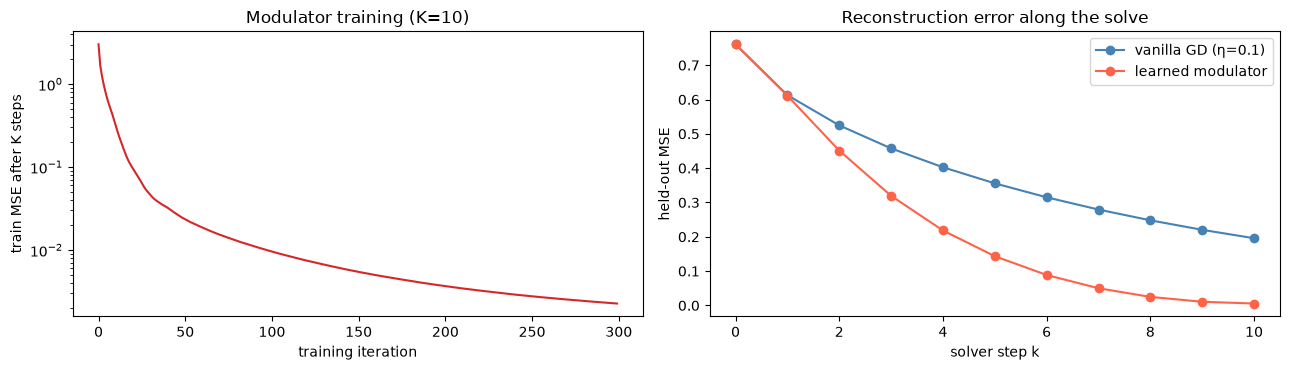

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

axes[0].semilogy(train_hist, color="tab:red")
axes[0].set_xlabel("training iteration")
axes[0].set_ylabel("train MSE after K steps")
axes[0].set_title(f"Modulator training (K={K})")

axes[1].plot(gd_trace, marker="o", color="steelblue", label=f"vanilla GD (η={ETA})")
axes[1].plot(lm_trace, marker="o", color="tomato", label="learned modulator")
axes[1].set_xlabel("solver step k")
axes[1].set_ylabel("held-out MSE")
axes[1].set_title("Reconstruction error along the solve")
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Ablation — number of solver steps $K$

For each $K$ we train a fresh modulator *at that* $K$ and compare its
held-out MSE with vanilla gradient descent run for the same number of
steps.

Two things to keep separate when reading the plot. Vanilla descent
lowers $U$ at every step, but the plotted quantity is held-out
reconstruction MSE, a different objective: in this run the MSE happens to
fall with $K$, and there is no guarantee it must — once close to a
stationary point of $U$, further descent can lower $U$ while moving away
from the truth. The learned solver is far ahead at small $K$ — one or two
learned steps beat fifteen plain ones — because it is not constrained to
be a descent method on $U$ at all. Its own curve need not be monotone
either: a longer unroll is a harder training problem (the product of
Jacobians above) with the same iteration budget, so the modulator trained
at large $K$ can end slightly worse than the one trained at moderate $K$.
In practice 4DVarNet uses $K \sim 10$–$15$ for exactly this reason, and
chapter [9](../09_4dvarnet.md) discusses the one-step and implicit
adjoints that make larger $K$ trainable.

In [7]:
K_VALUES = [1, 2, 5, 10, 15]
mse_gd, mse_learned = [], []
for k in K_VALUES:
    _, tr = vanilla_gd_trace(batch_test, k)
    mse_gd.append(float(tr[-1]))
    gm_k, _ = train_grad_mod(make_grad_mod(1), batch_train, n_steps=k, n_iters=200)
    _, tr = learned_trace(gm_k, batch_test, k)
    mse_learned.append(float(tr[-1]))
    print(f"K={k:2d}: vanilla GD={mse_gd[-1]:.4f}  learned={mse_learned[-1]:.4f}")

K= 1: vanilla GD=0.6127  learned=0.0086


K= 2: vanilla GD=0.5247  learned=0.0043


K= 5: vanilla GD=0.3557  learned=0.0039


K=10: vanilla GD=0.1958  learned=0.0083


K=15: vanilla GD=0.1097  learned=0.0169


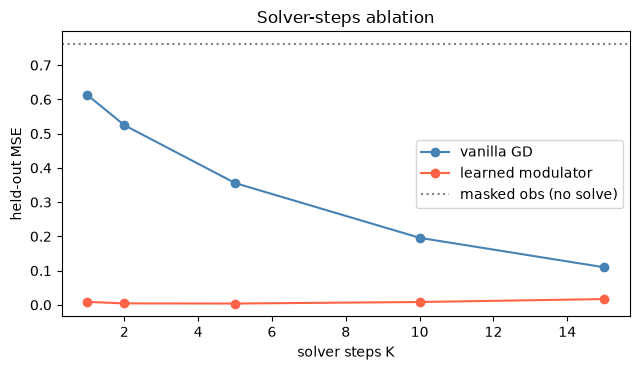

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(K_VALUES, mse_gd, marker="o", color="steelblue", label="vanilla GD")
ax.plot(K_VALUES, mse_learned, marker="o", color="tomato", label="learned modulator")
ax.axhline(float(gd_trace[0]), color="gray", linestyle=":", label="masked obs (no solve)")
ax.set_xlabel("solver steps K")
ax.set_ylabel("held-out MSE")
ax.set_title("Solver-steps ablation")
ax.legend()
plt.tight_layout()
plt.show()

## Summary

- A solver is an update rule; learning it is a bilevel problem whose
  outer objective is the reconstruction error after $K$ steps and whose
  outer variable is the rule itself.
- With the prior frozen, replacing the fixed gradient step by a trained
  `ConvLSTMGradMod1D` is what buys the fast convergence of 4DVarNet: the
  modulator learns step sizes, momentum, and preconditioning from data,
  and — because it is trained on the truth rather than on $U$ — it can
  land closer to the truth than descent on $U$ does.
- `solve_4dvarnet_1d` / `solver_step_1d` expose the solver as plain
  functions, so partial training is a matter of which argument you
  differentiate.
- `FourDVarNet1D` (notebook [03](03_4dvarnet_L63.ipynb)) trains the prior and
  the modulator jointly; chapter [9](../09_4dvarnet.md) gives the full
  picture and the adjoint options for long unrolls.